# Physics-Informed Extrapolation of Sectoral Fossil CO₂ Emissions in the Energy Transition: Stoichiometry as a Post-Forecast Correction
Companion notebook. It loads the saved outputs of the pipeline and reproduces every table and figure in the paper.
Heavy steps (model training, about 4–5 hours on two cores) are run by `run_all.sh`; the last section shows how to
re-run the light steps (evaluation, projections, figures) from here.

In [1]:
import json, os
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
def fig(name, width=900):
    display(Image(filename=f"figs/{name}", width=width))

## 1. Data and the stoichiometric audit

In [2]:
panel = pd.read_csv("data/panel.csv")
countries = pd.read_csv("data/panel_countries.csv")
print(f"{countries.shape[0]} countries, {len(panel):,} country-years; share of world fossil CO2 in 2022: "
      f"{countries.share_world_2022_pct.sum():.1f}%")
countries.sort_values("co2_2022_mt", ascending=False).head(10)

42 countries, 2,520 country-years; share of world fossil CO2 in 2022: 81.2%


,country,iso_code,complete_years,co2_2022_mt,share_world_2022_pct
0,China,CHN,45,11711.807620,31.208373
1,United States,USA,55,5055.402832,13.471097
2,India,IND,55,2831.131592,7.544097
3,Russia,RUS,40,1675.460815,4.464589
4,Japan,JPN,55,1029.644897,2.743688
5,Iran,IRN,55,767.178467,2.044295
6,Indonesia,IDN,55,758.020508,2.019892
7,Saudi Arabia,SAU,45,666.993530,1.777333
8,Canada,CAN,55,547.657654,1.459340
9,Brazil,BRA,55,480.058289,1.279208


In [3]:
D = pd.read_csv("data/ef_diagnostic.csv")
(D.groupby("fuel").band_class.value_counts(normalize=True).unstack() * 100).round(1)

band_class,above_upper,below_lower,within
fuel,,,
coal,6.1,22.9,71.0
gas,24.9,44.6,30.4
oil,6.5,21.6,71.9


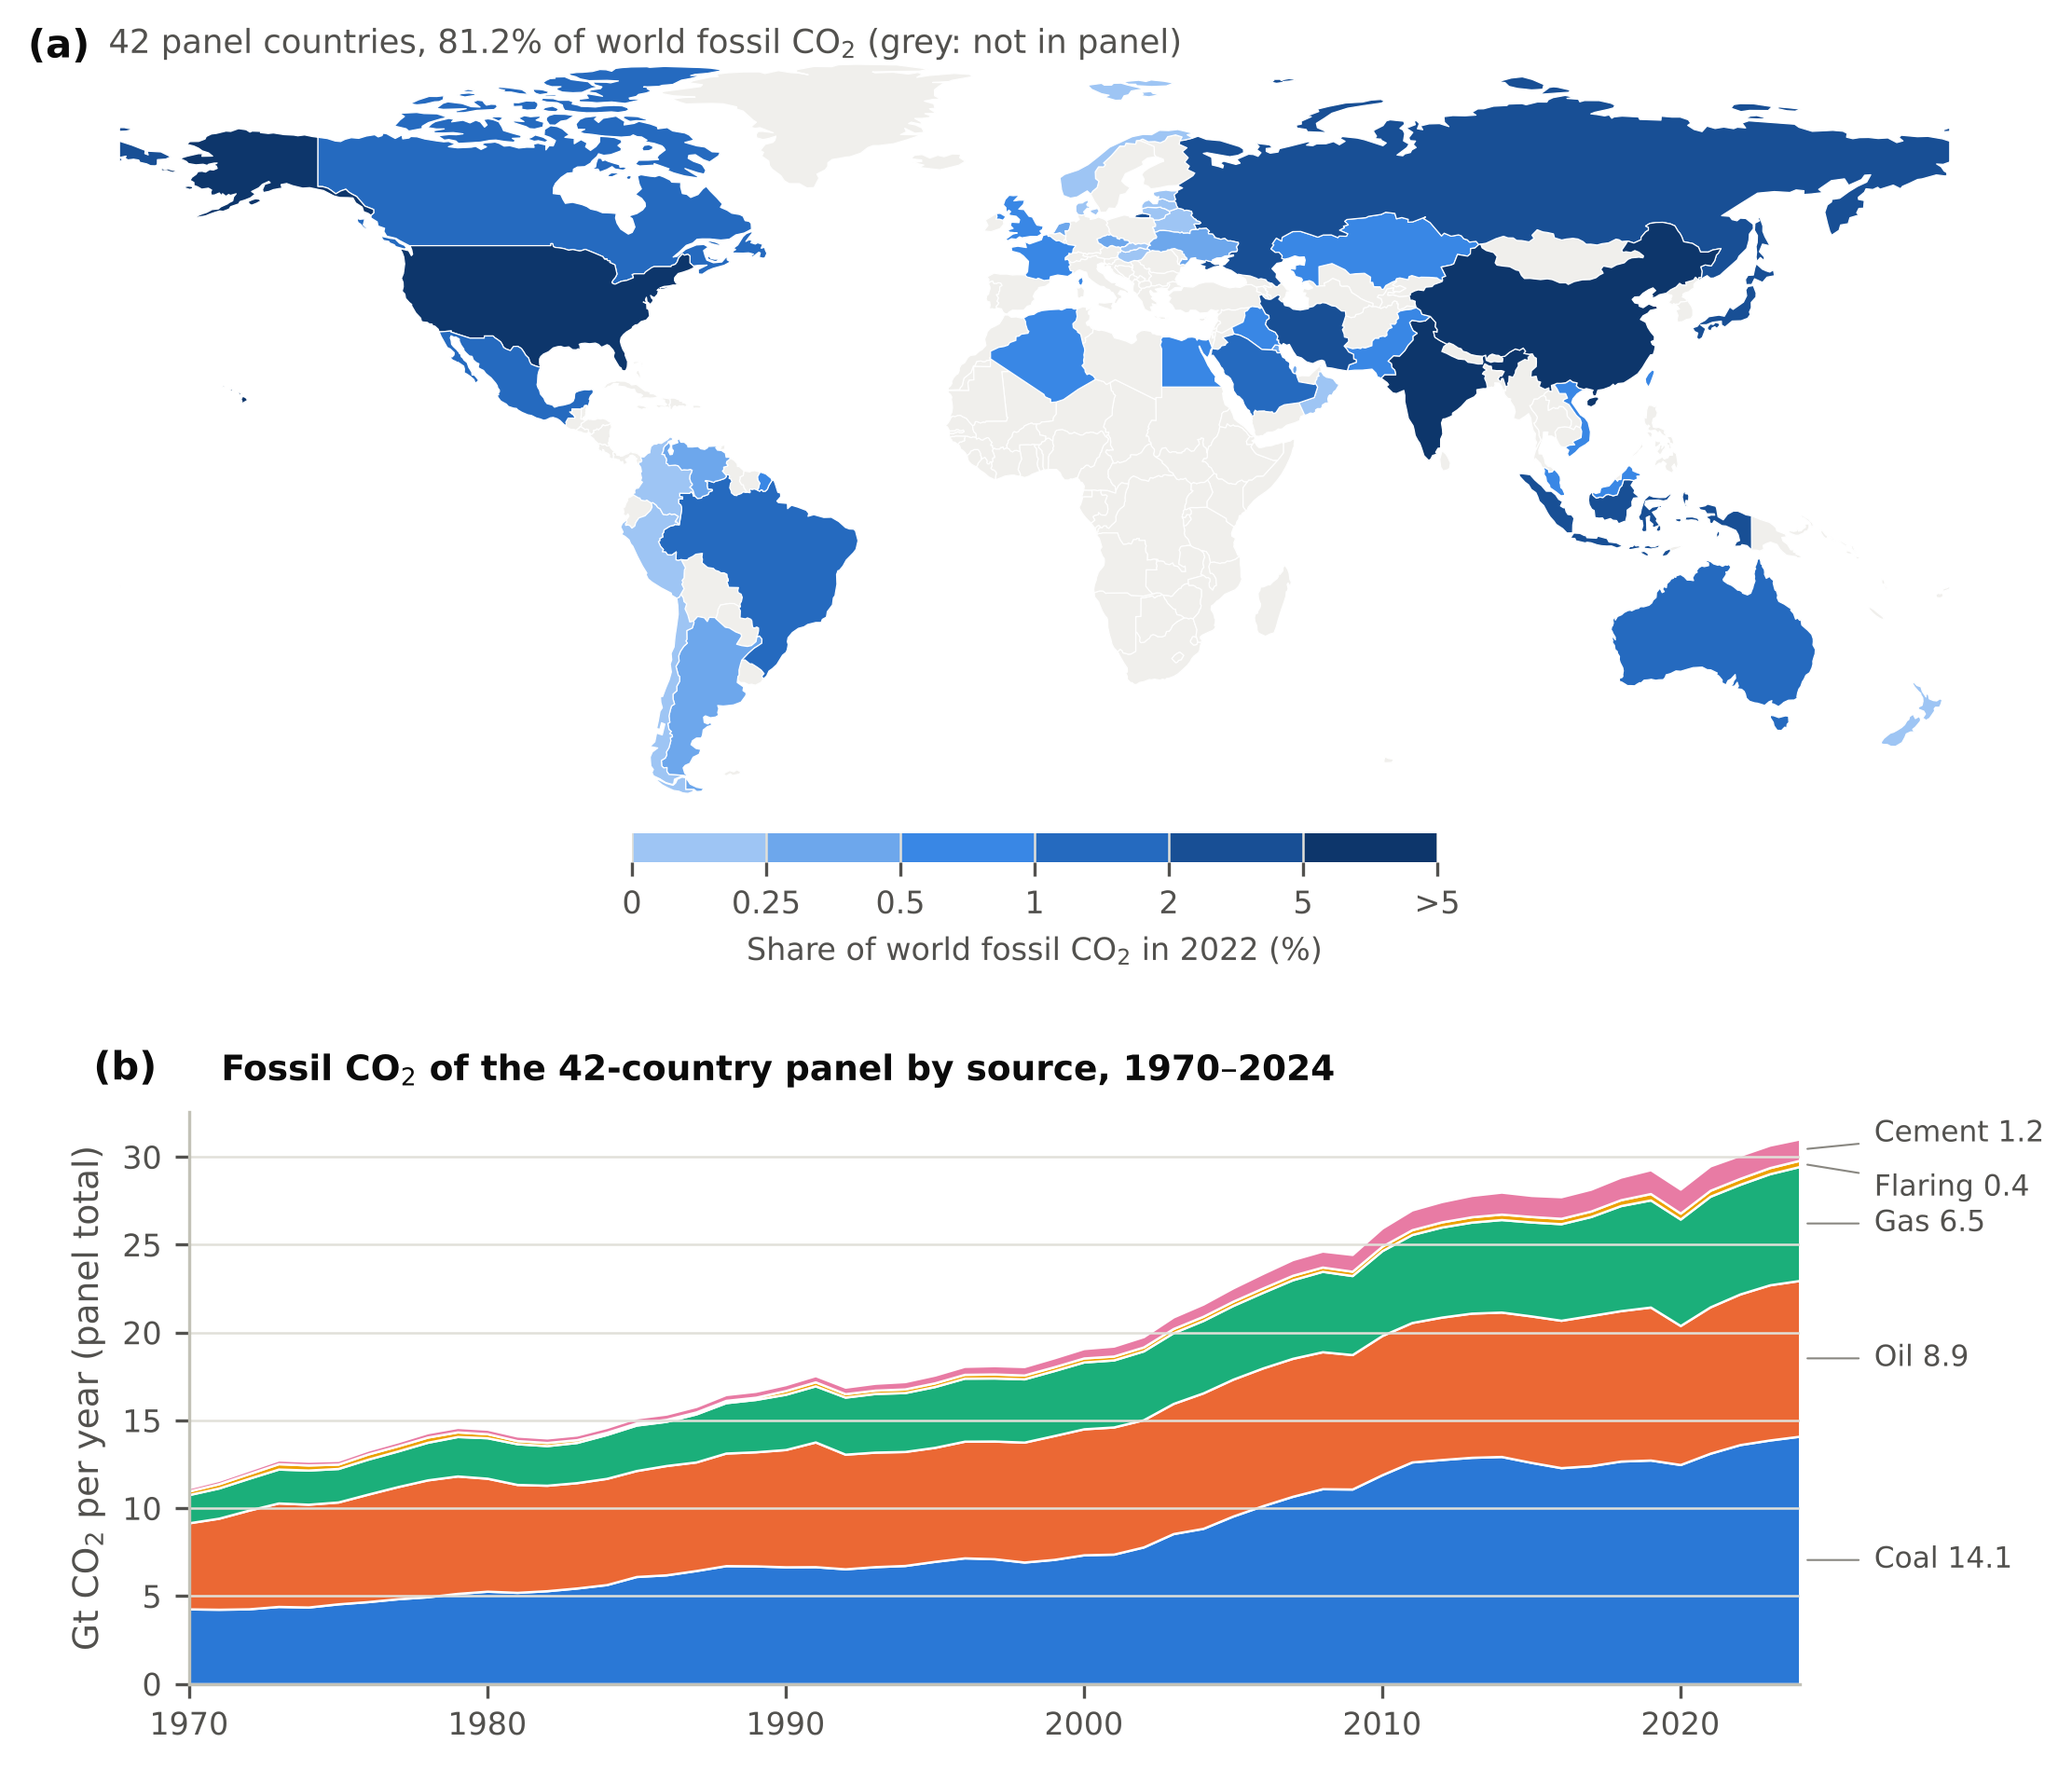

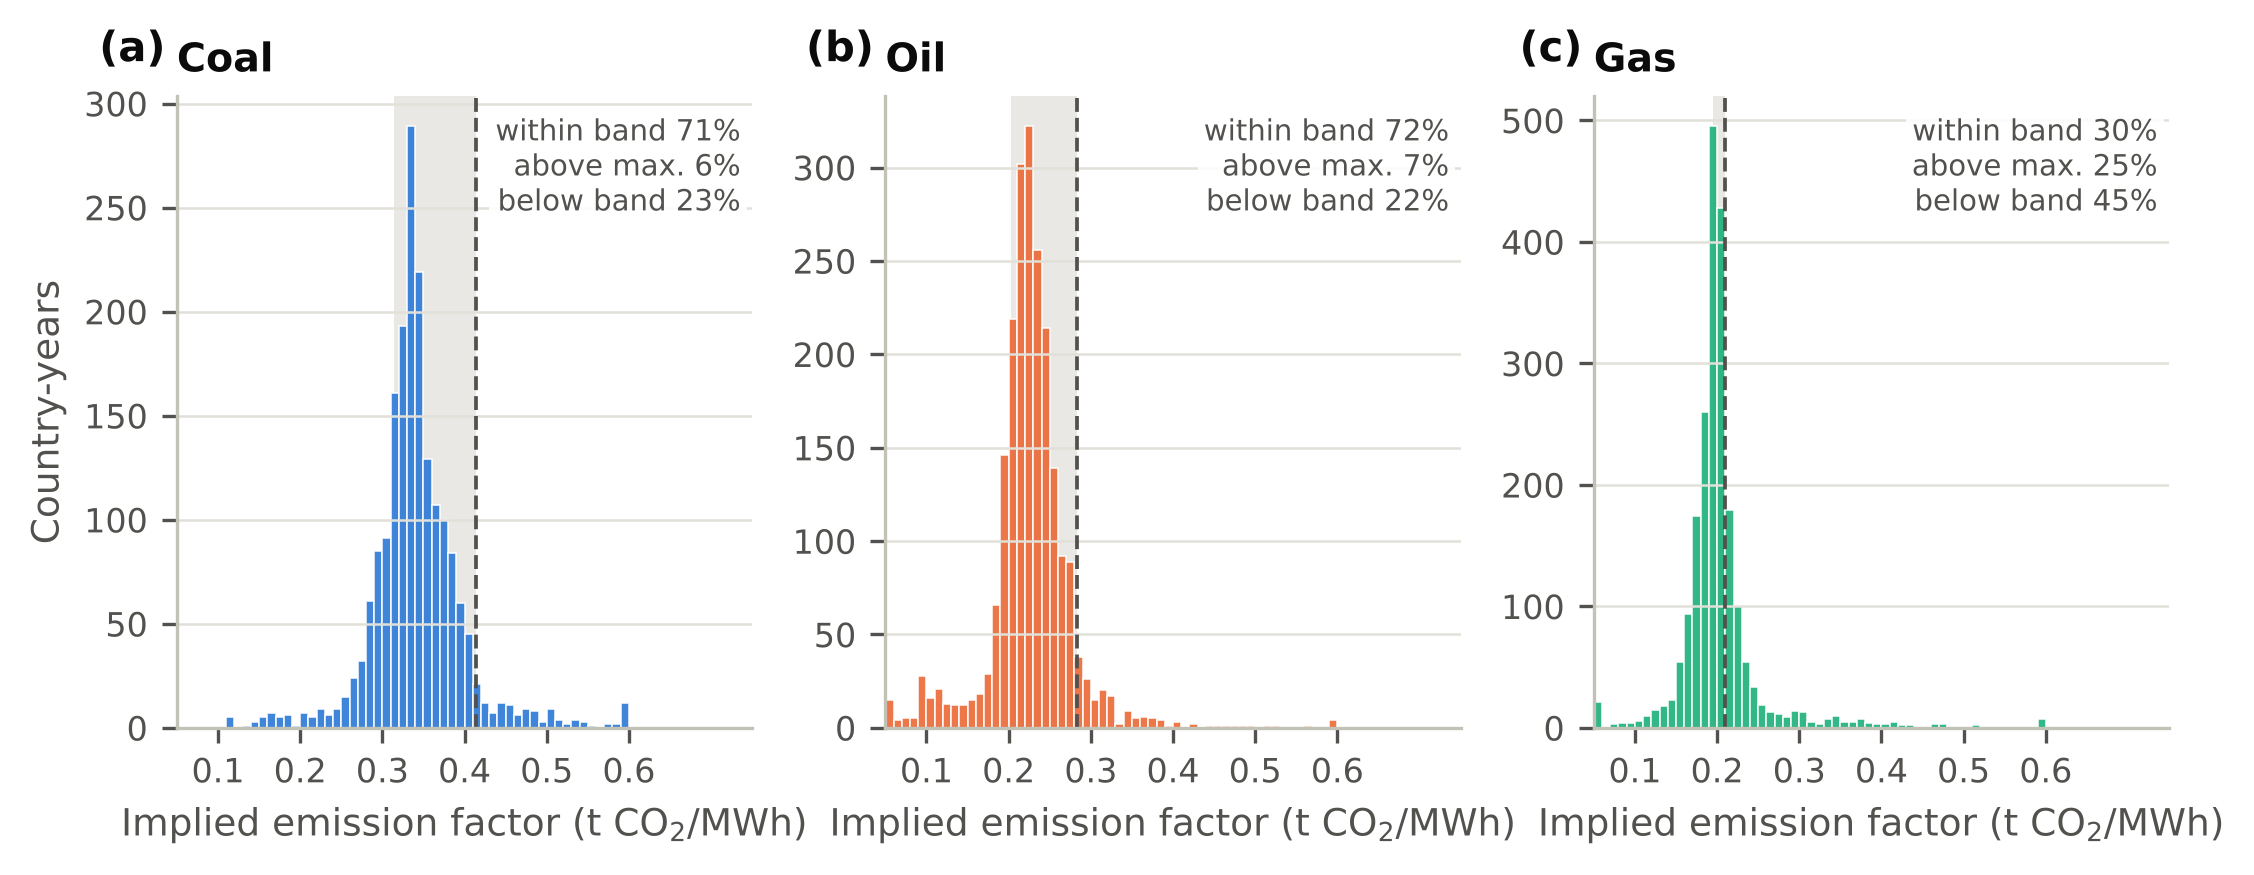

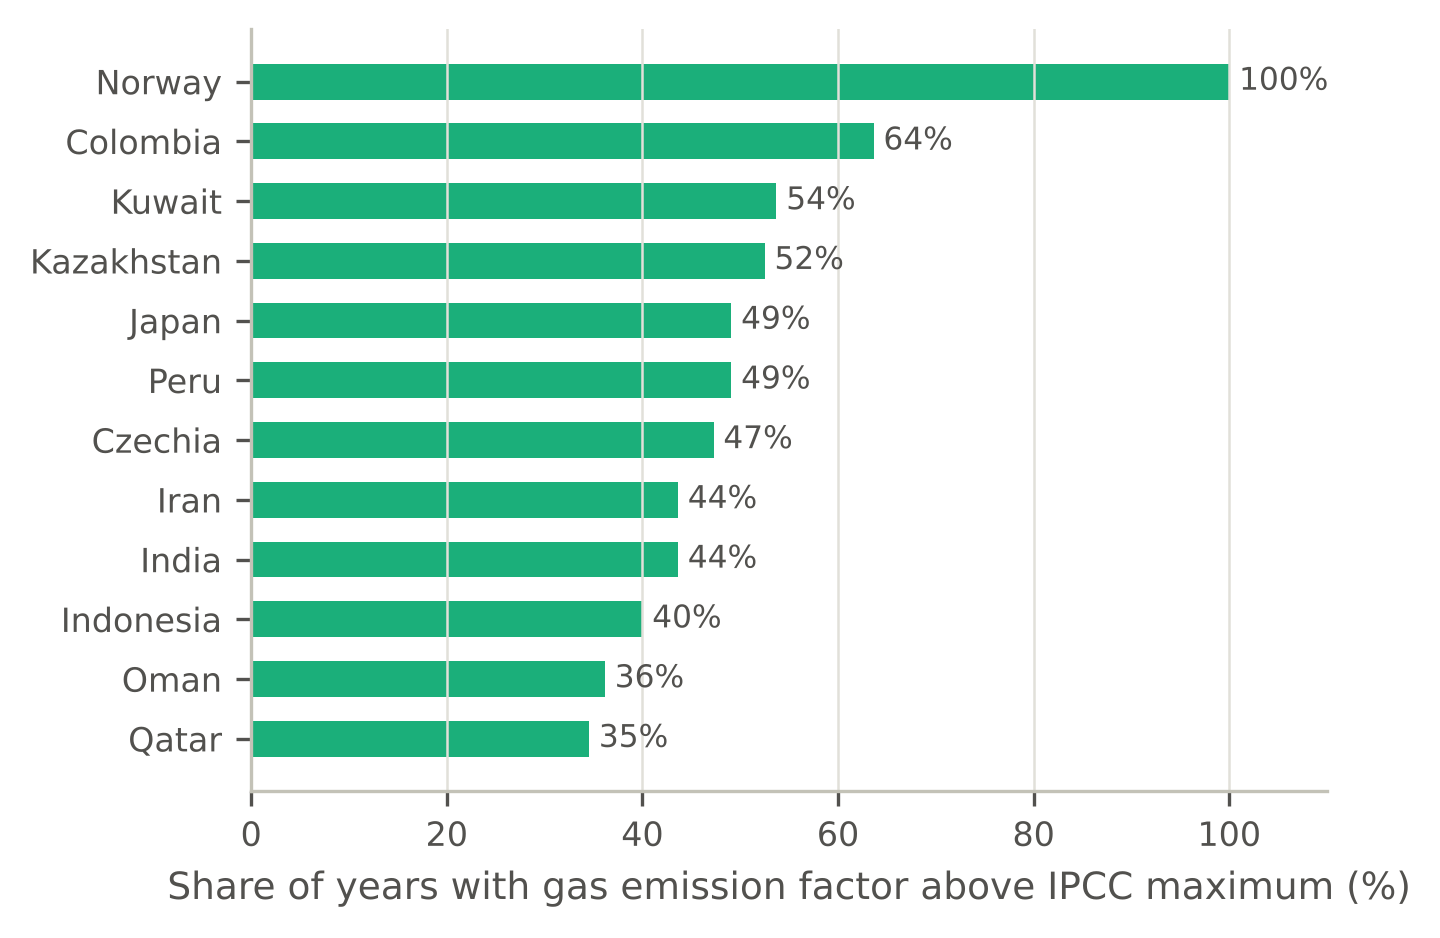

In [4]:
fig("fig2_panel.png"); fig("fig3_ef_diagnostic.png"); fig("figS1_gas_above_max.png", 600)

## 2. Development period and the recorded model-selection decision

In [5]:
print(open("results/dev/dev_scores.txt").read())
pre = json.load(open("results/dev/preregistration.json"))
print(json.dumps({k: pre[k] for k in ["recorded_at", "basis", "decision"]}, indent=1))

dev rows: 1470 (origins 1998-2002, targets <= 2007)
  naive    MASE sectors 4.0931  total 3.6373
  trend    MASE sectors 11.1532  total 4.6643
  damped   MASE sectors 3.4389  total 2.5300
results/dev/xgb_d3_n300.pkl XGB-E:3.7643/2.9134 XGB-D:3.7510/2.9609 XGB-H:3.7784/2.8982 XGB-P:3.7239/2.8857
results/dev/xgb_d3_n600.pkl XGB-E:3.8188/2.9401 XGB-D:3.7975/3.0091 XGB-H:3.8279/2.9310 XGB-P:3.7696/2.9352
results/dev/xgb_d5_n300.pkl XGB-E:3.7345/2.8466 XGB-D:3.6941/2.9119 XGB-H:3.7028/2.8597 XGB-P:3.6604/2.8457
results/dev/xgb_d5_n600.pkl XGB-E:3.7477/2.8619 XGB-D:3.7041/2.8986 XGB-H:3.7072/2.8525 XGB-P:3.6659/2.8380
results/dev/nnS_lam0.1.pkl NN-S:3.6670/2.9808
results/dev/nnS_lam1.0.pkl NN-S:3.7098/3.0281
results/dev/nnS_lam10.0.pkl NN-S:4.9188/5.1880
results/dev/nnU_w128_p0.1.pkl NN-U:3.8784/3.1186 NN-P:3.8542/3.0646
results/dev/nnU_w128_p0.3.pkl NN-U:3.6484/2.8768 NN-P:3.6470/2.9004
results/dev/nnU_w64_p0.1.pkl NN-U:3.9291/3.1644 NN-P:3.9152/3.0986
results/dev/nnU_w64_p0.3.pkl NN-U:3.66

In [6]:
json.load(open("results/dev/nn_choice.json"))

{'width': 128,
 'dropout': 0.3,
 'grid': [{'file': 'results/dev/nnU_w128_p0.1.pkl',
   'width': 128,
   'dropout': 0.1,
   'mase': 3.87842024410773,
   'mase_total': 3.1185529825075236},
  {'file': 'results/dev/nnU_w128_p0.3.pkl',
   'width': 128,
   'dropout': 0.3,
   'mase': 3.6483565654253507,
   'mase_total': 2.876833371609753},
  {'file': 'results/dev/nnU_w64_p0.1.pkl',
   'width': 64,
   'dropout': 0.1,
   'mase': 3.9290556980826294,
   'mase_total': 3.1643639182860195},
  {'file': 'results/dev/nnU_w64_p0.3.pkl',
   'width': 64,
   'dropout': 0.3,
   'mase': 3.66850061980333,
   'mase_total': 3.040313416111304}],
 'lam': 0.1,
 'lam_grid': [{'file': 'results/dev/nnS_lam0.1.pkl',
   'lam': 0.1,
   'mase': 3.666950101794893,
   'mase_total': 2.9807890449561327},
  {'file': 'results/dev/nnS_lam1.0.pkl',
   'lam': 1.0,
   'mase': 3.7098353291068573,
   'mase_total': 3.0280989906057263},
  {'file': 'results/dev/nnS_lam10.0.pkl',
   'lam': 10.0,
   'mase': 4.918790177893191,
   'mase_to

## 3. Test-period accuracy (Table 1, Fig. 4)

In [7]:
S = pd.read_csv("results/summary_table.csv").set_index("model")
S[["mase_1", "mase_2-3", "mase_4-6", "mase_7-10", "mase_all", "rel_all", "masetot_all", "reltot_all"]].round(3)

,mase_1,mase_2-3,mase_4-6,mase_7-10,mase_all,rel_all,masetot_all,reltot_all
model,,,,,,,,
naive,1.436,2.506,3.933,5.795,3.924,1.000,3.986,1.000
trend,1.550,3.110,6.380,17.775,8.770,1.531,5.618,1.332
damped,1.512,2.824,15.330,2706.099,882.189,1.200,58.008,1.164
damped-H,1.493,2.837,15.812,2723.379,887.946,1.188,58.033,1.120
damped-P,1.485,2.782,15.271,2706.370,882.244,1.172,57.725,1.119
XGB-E,1.636,2.461,3.722,5.537,3.783,1.190,3.278,0.977
XGB-D,1.641,2.464,3.721,5.473,3.763,1.189,3.317,0.984
XGB-P,1.610,2.443,3.688,5.437,3.732,1.177,3.332,0.972
XGB-H,1.628,2.471,3.731,5.511,3.779,1.188,3.430,0.986


In [8]:
R = pd.read_csv("results/covid_sensitivity.csv").set_index("model")
R[["mdase_all", "n_se_over_50", "share_err_over_50"]].round(3)   # median scaled error and exploding forecasts

,mdase_all,n_se_over_50,share_err_over_50
model,,,
naive,1.968,73,0.054
trend,2.448,403,0.448
damped,2.122,111,0.995
damped-H,2.068,130,0.996
damped-P,2.057,115,0.995
XGB-E,2.071,25,0.018
XGB-D,2.069,32,0.023
XGB-P,2.034,36,0.026
XGB-H,2.050,44,0.032


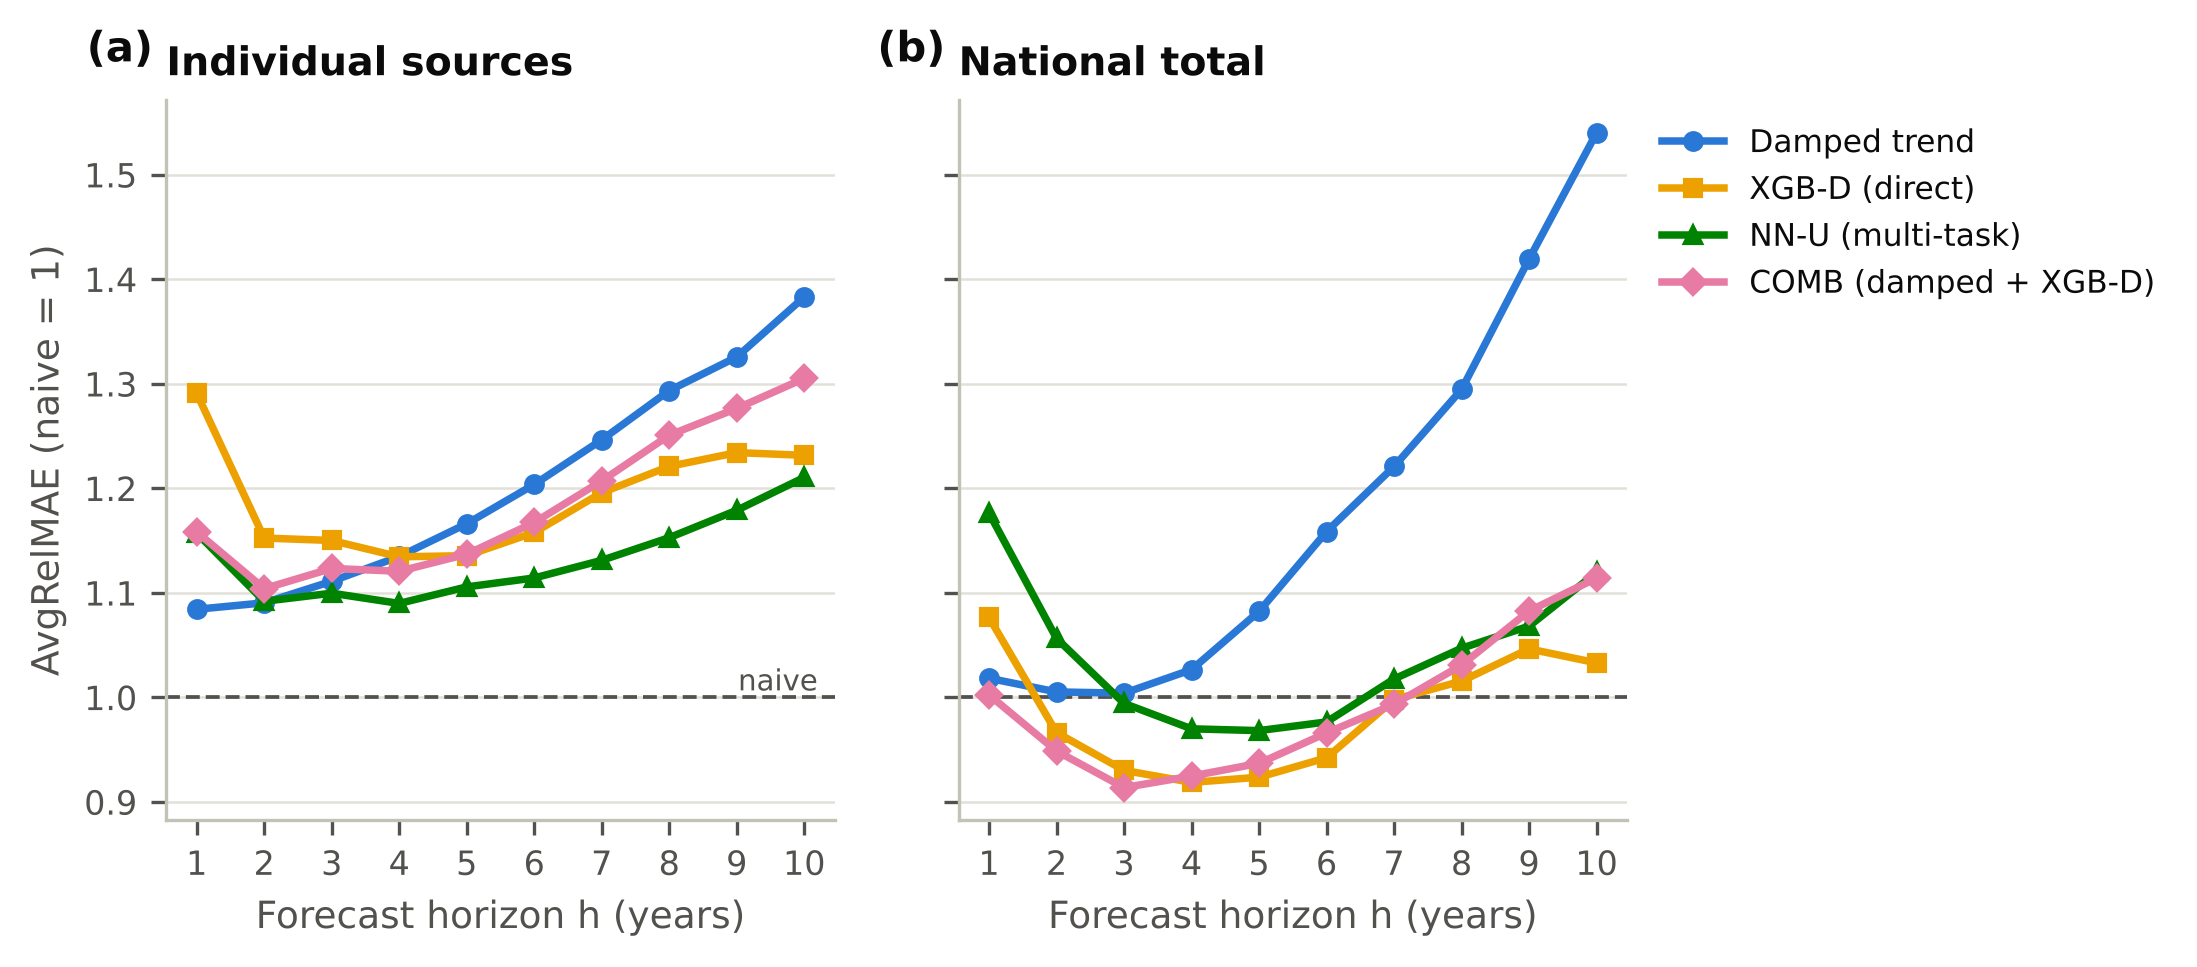

In [9]:
fig("fig4_accuracy_horizon.png")

## 4. Effect of the stoichiometric constraint (Table 2, Figs. 5–6)

In [10]:
T = pd.read_csv("results/significance_tests.csv")
T["cell"] = T.apply(lambda r: f"{r.rel_change_pct:+.1f}% [{r.ci_lo:+.1f}, {r.ci_hi:+.1f}] p_Holm={r.p_holm:.3f}", axis=1)
T[T.target == "sectors"].pivot_table(index=["a", "b"], columns="horizons", values="cell", aggfunc="first", sort=False)

horizons                                          1                                2-3                                4-6                                7-10
a        b                                                                                                                                                   
damped   naive     +8.3% [+4.2, +12.9] p_Holm=0.071  +10.2% [+4.4, +16.9] p_Holm=0.454  +17.2% [+7.5, +28.8] p_Holm=0.226  +31.6% [+14.7, +52.1] p_Holm=0.030
XGB-D    naive   +29.0% [+18.3, +45.4] p_Holm=0.000  +17.1% [+4.7, +34.5] p_Holm=1.000  +14.1% [+1.2, +31.1] p_Holm=1.000   +21.6% [+5.7, +42.5] p_Holm=0.310
         damped   +19.1% [+9.5, +31.5] p_Holm=0.002   +6.3% [-3.4, +18.1] p_Holm=1.000  -2.7% [-13.9, +10.8] p_Holm=1.000    -7.6% [-23.4, +9.1] p_Holm=1.000
         XGB-E      -0.2% [-3.3, +3.2] p_Holm=1.000    +0.4% [-2.0, +3.2] p_Holm=1.000    +0.1% [-2.9, +3.0] p_Holm=1.000     -0.7% [-3.8, +2.9] p_Holm=1.000
NN-U     naive    +15.7% [+7.8, +26.3] p_Holm=0.000  +11.4% [+2.1, +24.0] p_Holm=1.000  +10.3% [+0.8, +22.7] p_Holm=1.000   +16.7% [+4.2, +33.7] p_Holm=1.000
damped-H damped     -1.2% [-3.0, +0.7] p_Holm=1.000    -0.4% [-2.8, +2.0] p_Holm=1.000    -0.9% [-4.3, +2.3] p_Holm=1.000     -1.2% [-6.3, +3.8] p_Holm=1.000
damped-P damped     -1.5% [-2.6, -0.5] p_Holm=0.844    -1.4% [-2.7, -0.2] p_Holm=1.000    -2.2% [-4.1, -0.4] p_Holm=1.000     -3.0% [-5.6, -0.3] p_Holm=1.000
XGB-H    XGB-D      -1.2% [-3.1, +0.8] p_Holm=1.000    -0.1% [-1.7, +1.5] p_Holm=1.000    +0.0% [-2.1, +2.1] p_Holm=1.000     +0.1% [-2.3, +2.5] p_Holm=1.000
XGB-P    XGB-D      -2.1% [-3.2, -1.0] p_Holm=0.067    -1.0% [-1.9, -0.2] p_Holm=1.000    -1.0% [-2.1, +0.2] p_Holm=1.000     -0.9% [-2.2, +0.4] p_Holm=1.000
NN-S     NN-U       +0.4% [-0.7, +1.5] p_Holm=1.000    +0.1% [-1.1, +1.1] p_Holm=1.000    +0.1% [-1.6, +1.3] p_Holm=1.000     -1.0% [-2.8, +0.6] p_Holm=1.000
NN-P     NN-U       +0.3% [+0.0, +0.6] p_Holm=1.000    -0.1% [-0.4, +0.3] p_Holm=1.000    -0.1% [-0.5, +0.4] p_Holm=1.000     -0.2% [-0.8, +0.3] p_Holm=1.000
NN-H     NN-U       +1.1% [-0.8, +3.2] p_Holm=1.000    +0.5% [-0.9, +2.2] p_Holm=1.000    -0.1% [-1.7, +1.5] p_Holm=1.000     +1.0% [-0.9, +3.0] p_Holm=1.000
COMB     damped    +6.8% [+0.0, +16.5] p_Holm=1.000   +2.6% [-5.2, +12.8] p_Holm=1.000   -2.6% [-11.2, +7.3] p_Holm=1.000    -4.6% [-15.2, +6.8] p_Holm=1.000
         XGB-D    -11.0% [-13.4, -8.6] p_Holm=0.000    -3.8% [-6.2, -1.3] p_Holm=0.943    -0.4% [-4.0, +3.7] p_Holm=1.000    +2.8% [-3.5, +10.9] p_Holm=1.000
COMB-H   COMB       -0.7% [-2.2, +0.7] p_Holm=1.000    -0.1% [-1.5, +1.3] p_Holm=1.000    -0.7% [-2.6, +1.2] p_Holm=1.000     -1.2% [-4.1, +1.7] p_Holm=1.000
COMB-P   damped    +5.6% [-1.3, +15.2] p_Holm=1.000   +1.8% [-6.1, +12.6] p_Holm=1.000   -3.9% [-12.2, +5.6] p_Holm=1.000    -6.0% [-16.3, +6.2] p_Holm=1.000
         COMB       -1.1% [-1.9, -0.3] p_Holm=1.000    -0.8% [-1.6, -0.0] p_Holm=1.000    -1.3% [-2.4, -0.2] p_Holm=1.000     -1.5% [-3.1, +0.0] p_Holm=1.000

In [11]:
pd.read_csv("results/constraint_by_source.csv").pivot(index=["a", "b"], columns="source", values="rel_change_pct").round(1)

source           cement  coal  flaring   gas  oil
a        b                                       
COMB-H   COMB       0.0  -2.9      0.0  -3.4  2.3
COMB-P   COMB       0.0  -2.0      0.0  -3.1 -1.2
         damped    -9.2  -7.7     29.8 -12.0 -6.4
NN-H     NN-U      -0.4   0.2      2.6   1.3 -0.7
NN-P     NN-U       0.0  -0.3      0.0  -0.1 -0.1
NN-S     NN-U      -1.6  -1.5      2.2  -0.2 -0.3
XGB-H    XGB-D      0.0  -0.2      0.0  -0.2 -0.1
XGB-P    XGB-D      0.0  -1.1      0.0  -1.7 -2.5
damped-H damped     0.0  -6.2      0.0  -1.0  2.5
damped-P damped     0.0  -4.3      0.0  -3.3 -3.9

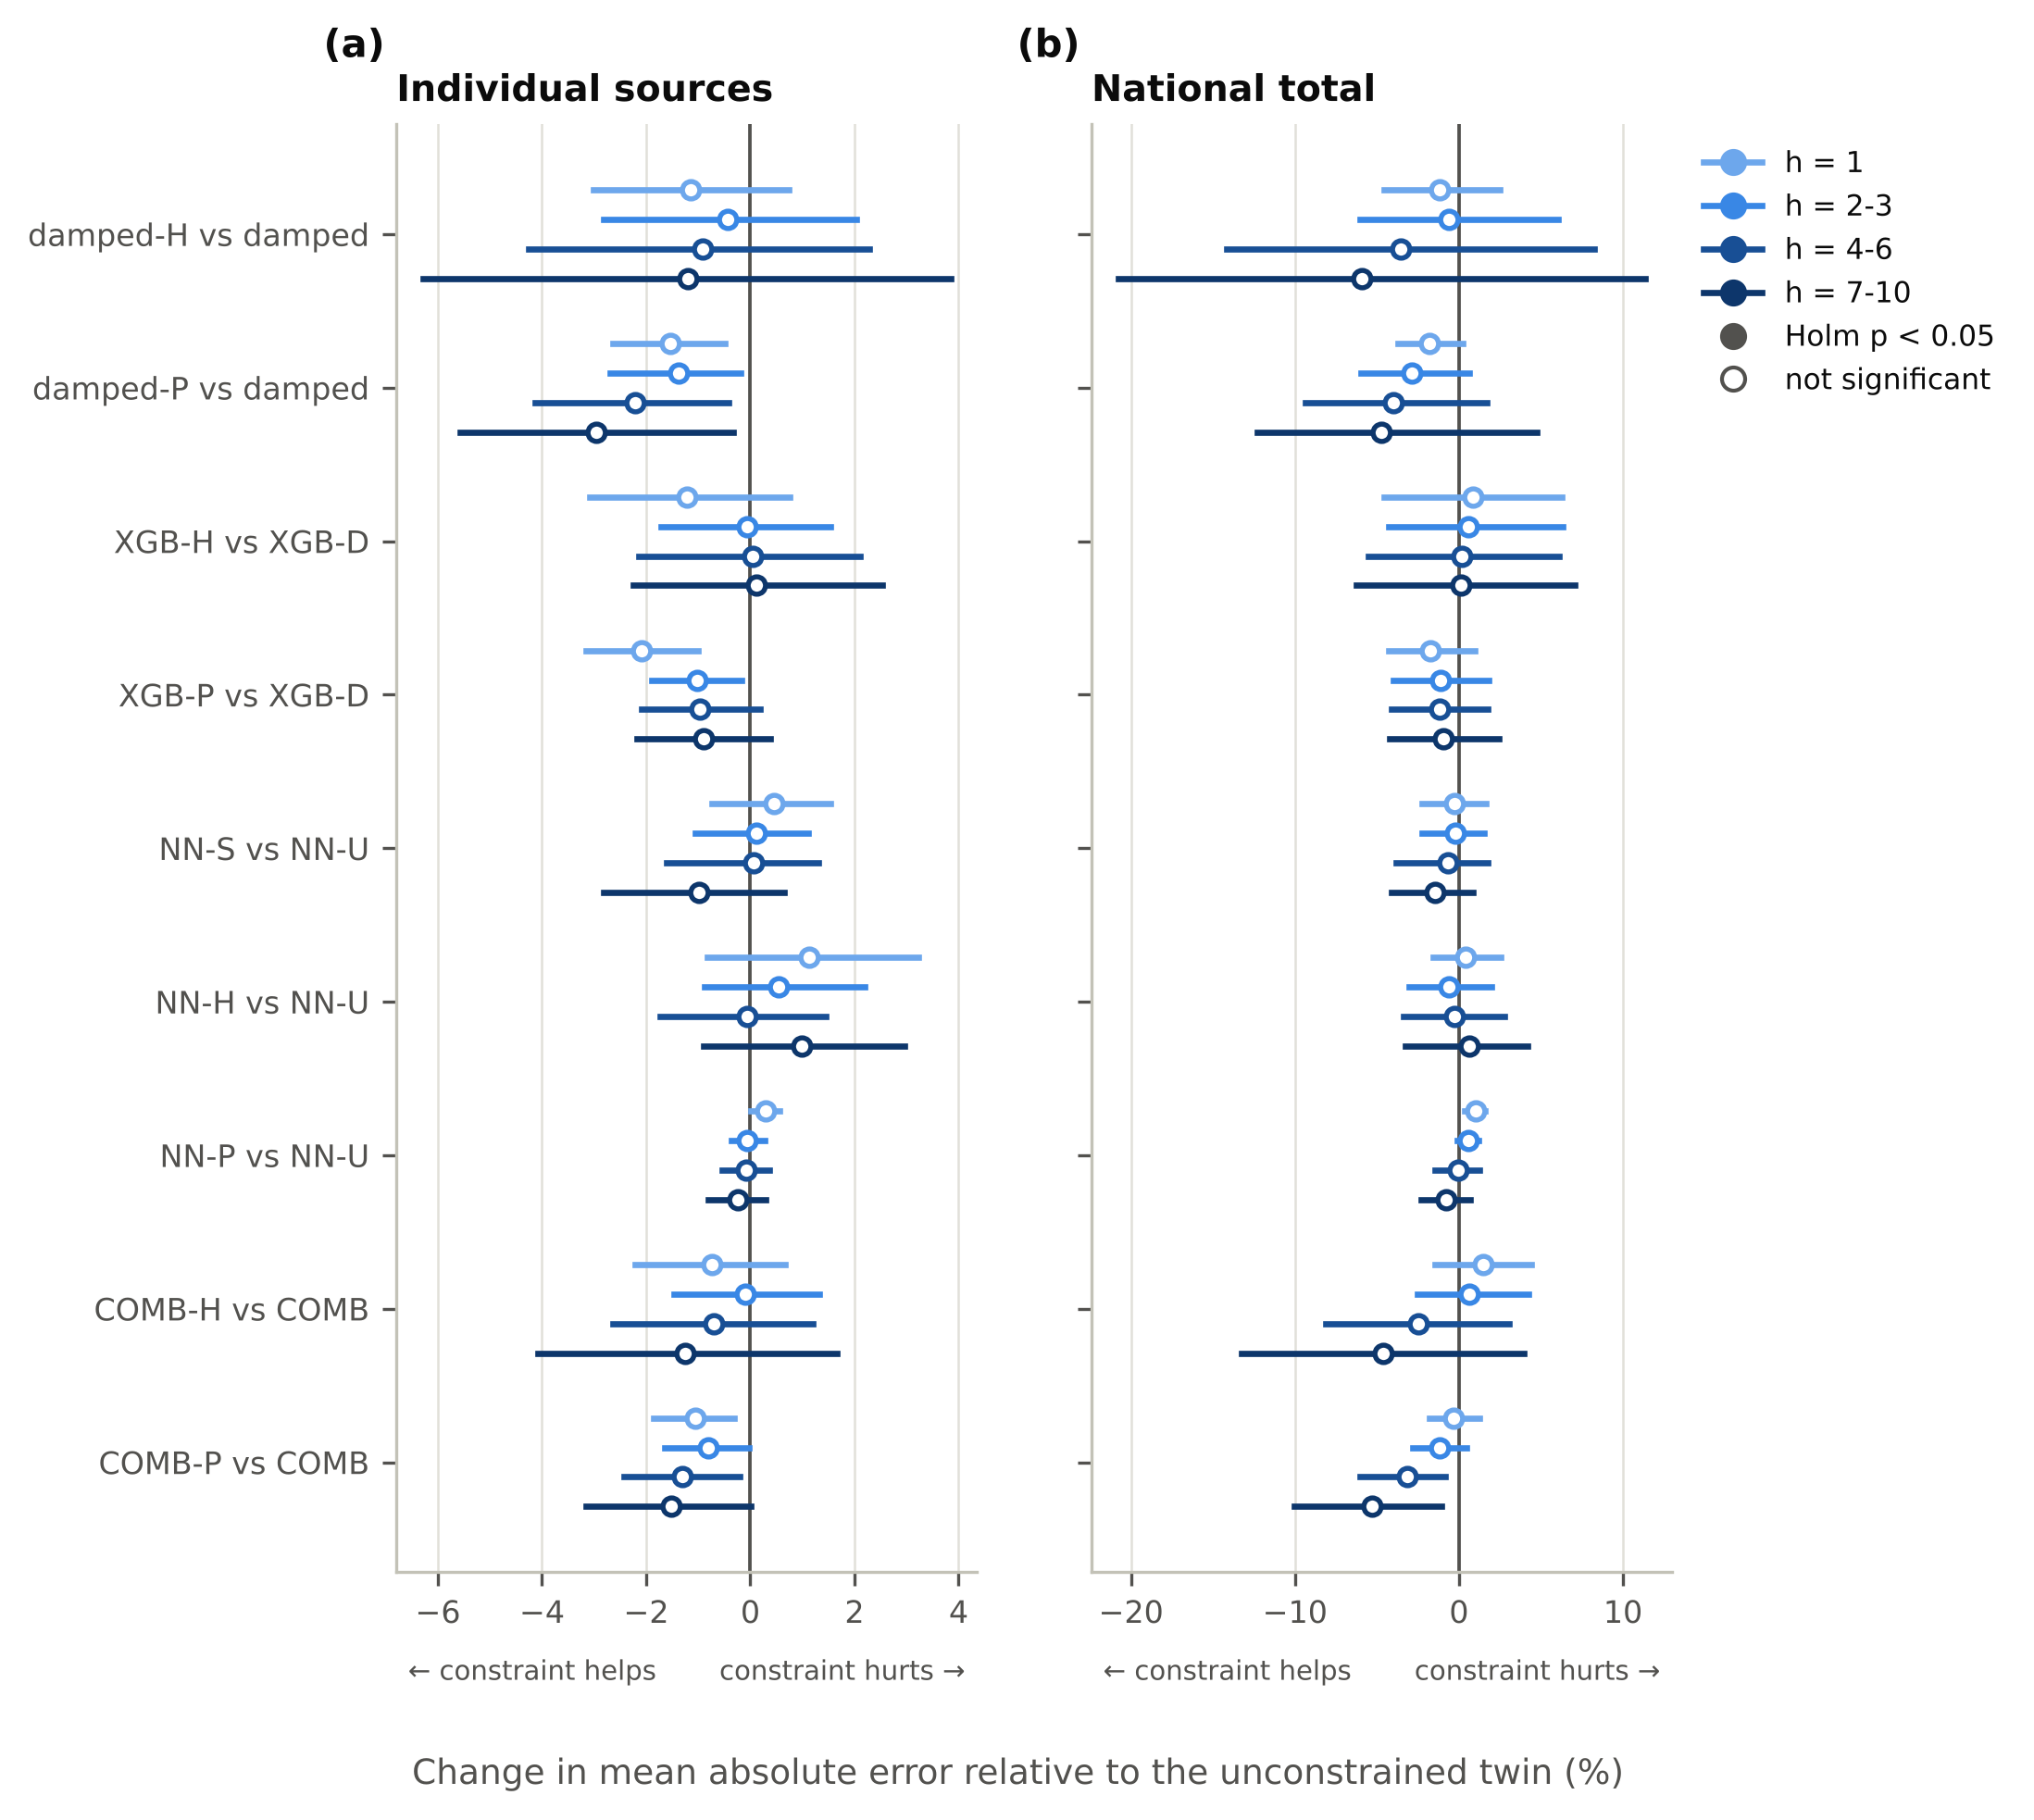

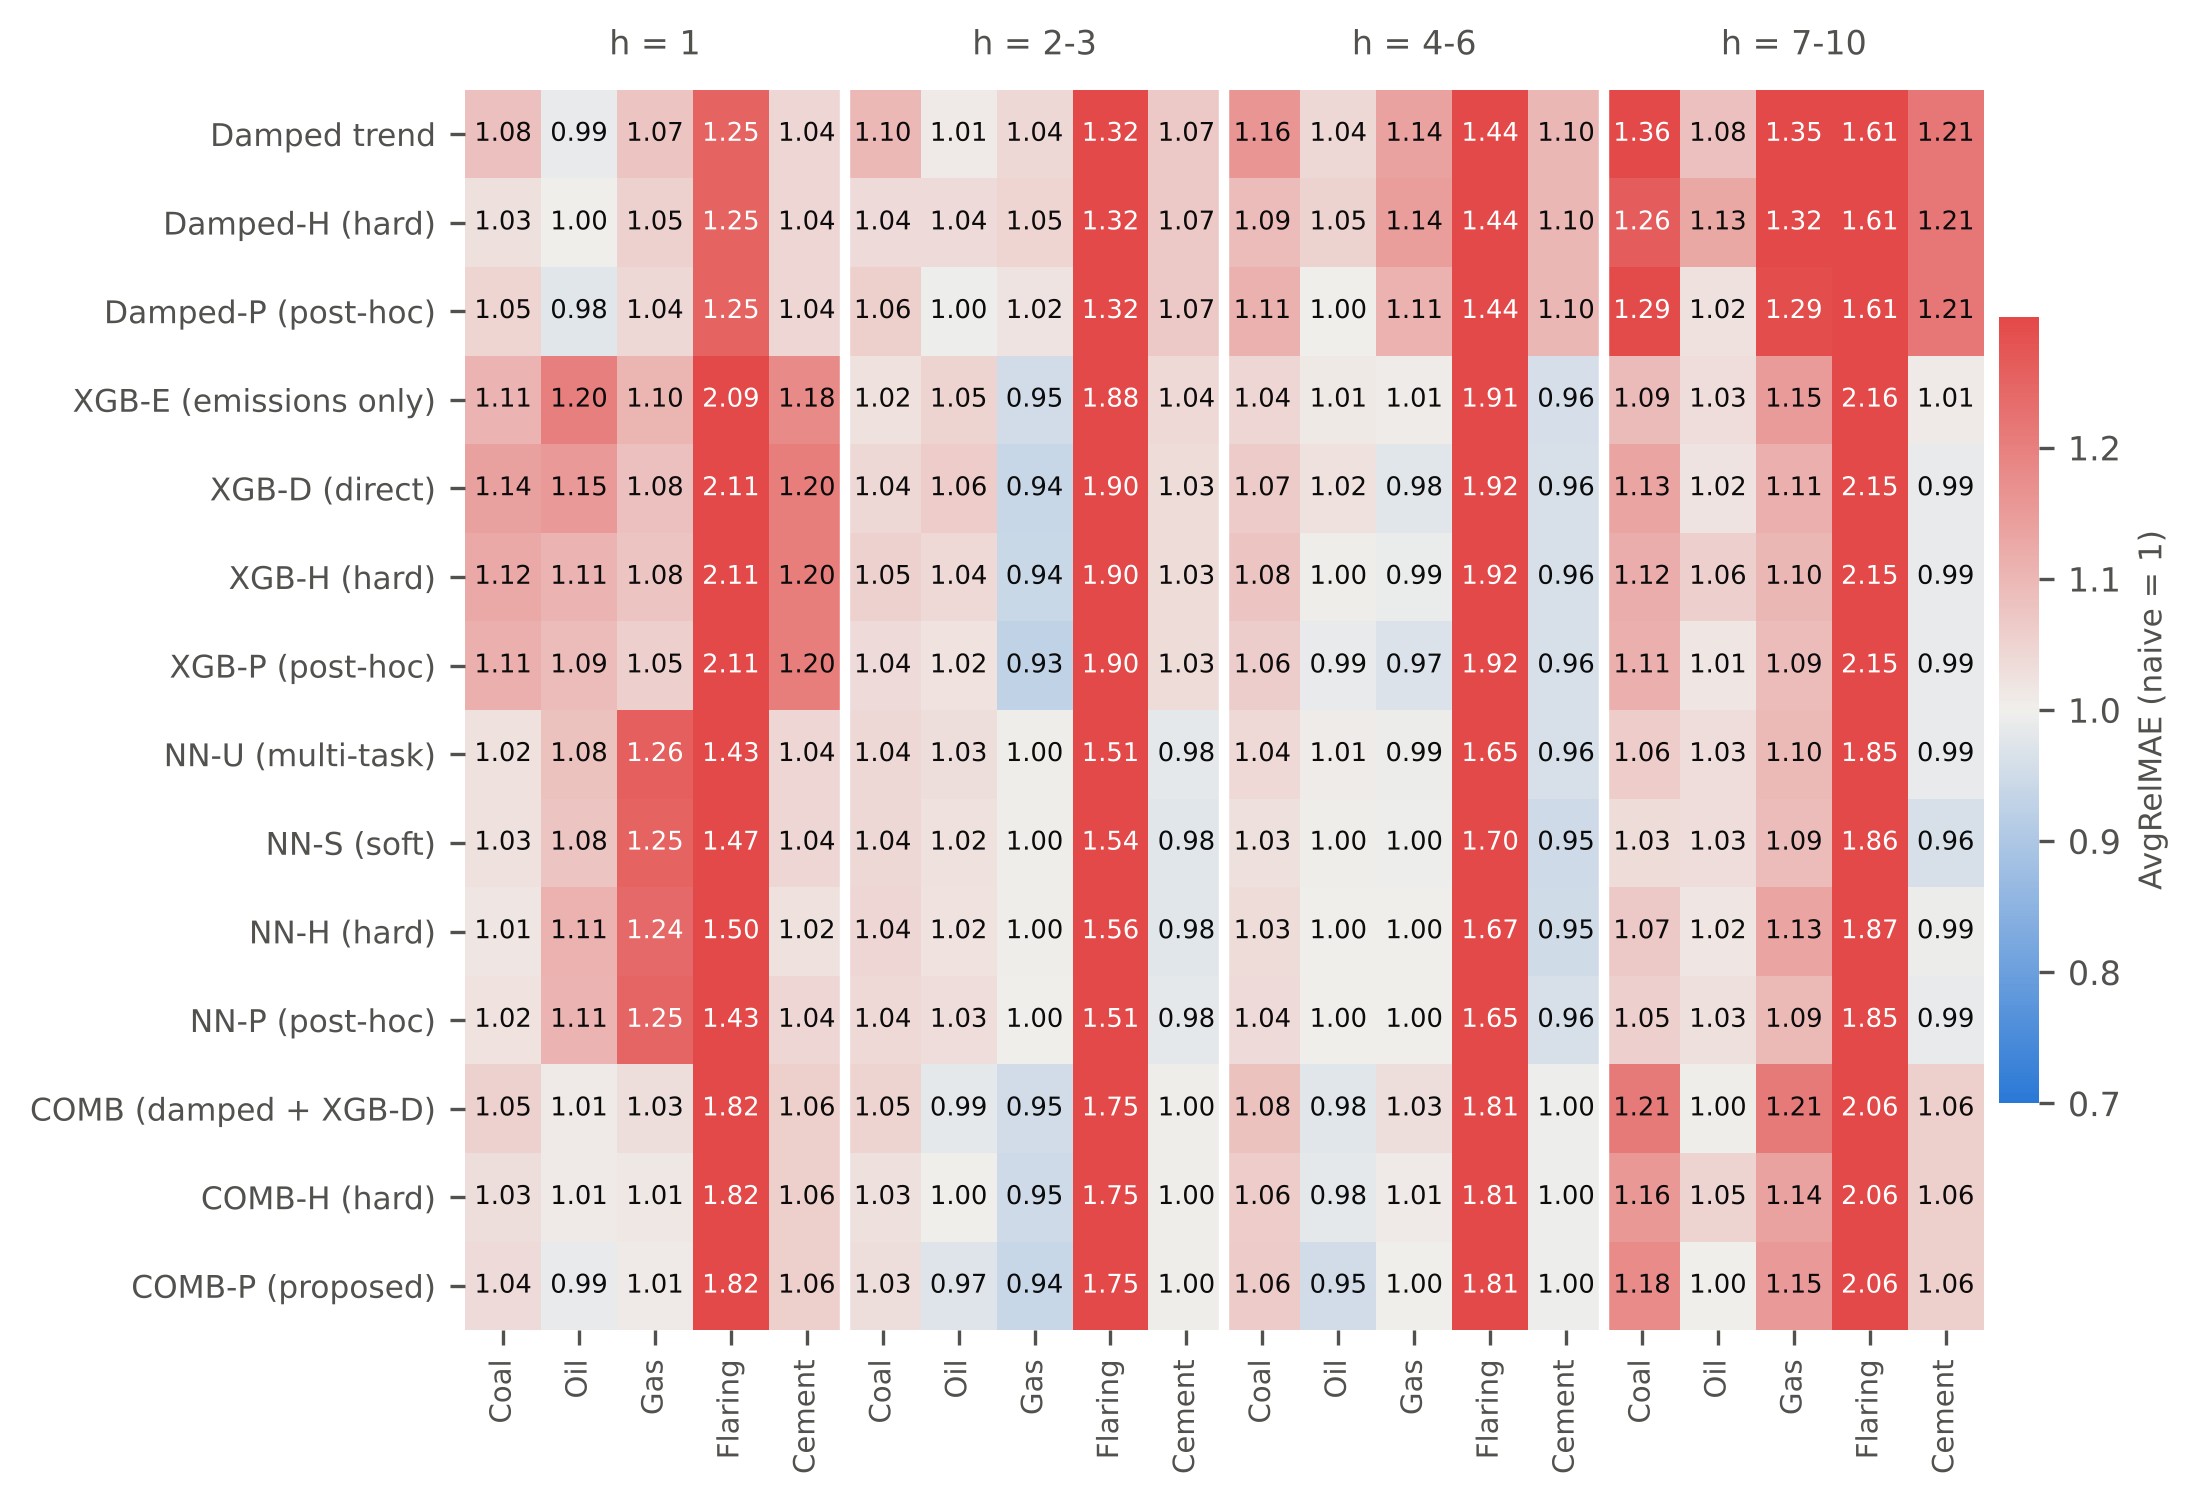

In [12]:
fig("fig5_physics_effect.png"); fig("fig6_source_heatmap.png")

## 5. Why the projection helps (Fig. 7) and fuel-energy accuracy

In [13]:
V = pd.read_csv("results/violation_by_horizon.csv")
t = V.pivot_table(index=["fuel", "h"], columns="model", values="implied_med") * 100
t["observed"] = V.groupby(["fuel", "h"]).observed_med.first() * 100
t.round(1)

model    COMB  NN-U  XGB-D  damped  observed
fuel h                                      
coal 1    1.5   0.4    2.8     1.0       1.7
     2    1.8   0.6    2.9     1.7       2.5
     3    1.9   0.9    3.0     2.2       2.9
     4    2.3   1.3    3.2     2.7       3.8
     5    2.4   1.5    3.6     3.1       4.1
     6    2.8   1.6    4.0     3.5       4.8
     7    3.2   1.7    4.4     3.6       5.2
     8    3.6   1.7    4.8     3.7       5.4
     9    3.9   1.8    4.9     3.8       6.4
     10   3.8   1.9    4.8     3.9       6.8
gas  1    1.3   0.4    2.0     1.5       1.3
     2    1.7   0.4    2.1     2.3       1.9
     3    2.3   0.7    2.5     3.2       2.4
     4    2.9   1.0    2.9     4.0       2.7
     5    3.1   1.3    3.5     4.7       2.9
     6    3.6   1.5    3.9     5.6       3.3
     7    4.1   1.7    4.0     6.5       3.1
     8    4.7   1.9    4.8     7.3       3.6
     9    5.1   2.1    4.9     8.4       4.1
     10   5.8   2.5    5.5     8.9       4.4
oil  1    1.3   0.8    2.2     0.9       2.5
     2    1.5   0.9    2.2     1.5       3.3
     3    1.8   1.0    2.5     2.0       4.5
     4    2.0   1.1    2.9     2.5       4.8
     5    2.2   1.3    3.0     2.9       4.8
     6    2.4   1.4    3.6     3.4       5.3
     7    2.7   1.6    3.8     3.8       5.1
     8    3.2   1.7    4.1     4.0       5.6
     9    3.3   1.8    4.4     4.2       5.9
     10   3.4   1.8    4.5     4.3       6.0

In [14]:
E = pd.read_csv("results/energy_accuracy.csv")
E.pivot(index="model", columns="group", values="mase_energy").round(2)

group,1,2-3,4-6,7-10,all
model,,,,,
COMB,1.55,2.58,4.21,6.85,4.39
COMB-H,1.55,2.58,4.21,6.85,4.39
COMB-P,1.57,2.58,4.13,6.44,4.23
NN-H,1.67,2.61,4.04,5.95,4.06
NN-H-band,1.67,2.61,4.04,5.95,4.06
NN-P,1.70,2.61,4.05,5.86,4.04
NN-S,1.68,2.59,4.01,5.73,3.98
NN-U,1.70,2.61,4.06,5.82,4.03
XGB-D,1.68,2.59,4.11,6.21,4.17


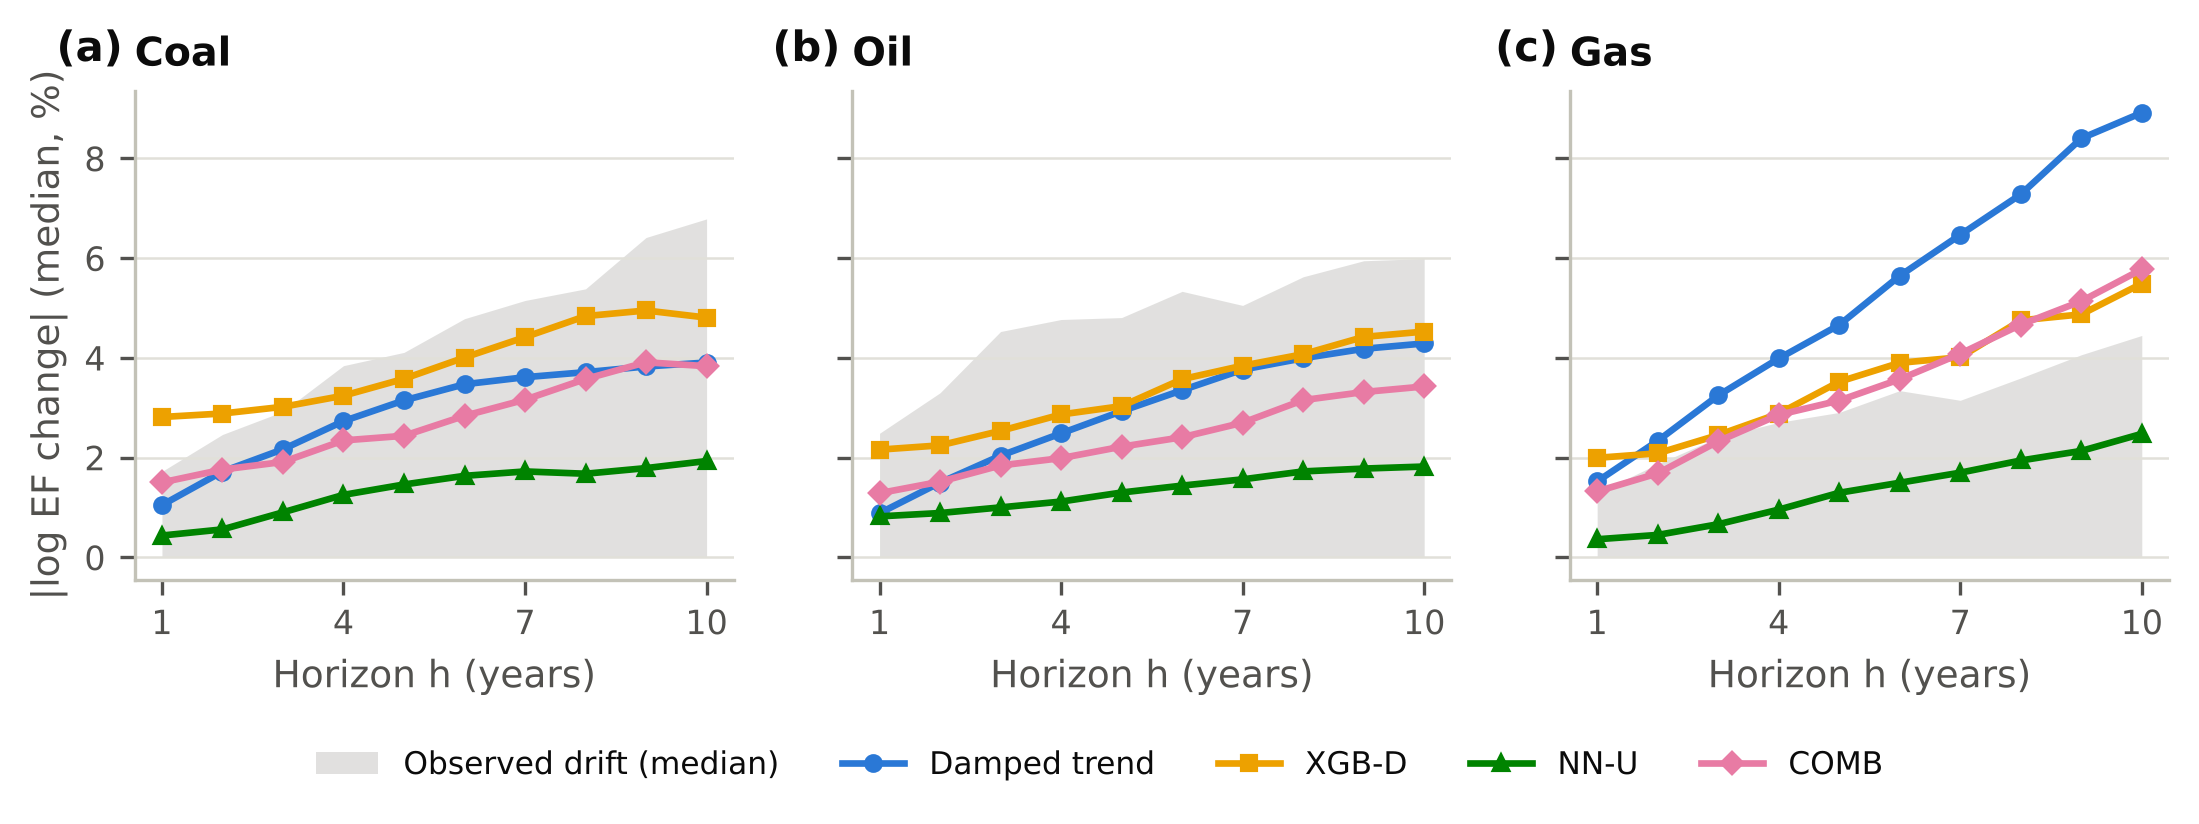

In [15]:
fig("fig7_violation.png")

## 5b. Supplementary: weighted correction (Table A.4) and energy-to-CO₂ conversion (Table 6)

In [16]:
pd.read_csv("results/weighted_tests.csv").query("horizons == 'all'")[["model", "versus", "rel_change_pct", "ci_lo", "ci_hi", "n_better"]].round(2)

,model,versus,rel_change_pct,ci_lo,ci_hi,n_better
8,damped-W,unconstrained,-1.58,-2.95,-0.20,28
9,damped-W,equal-weight,0.81,-0.09,1.83,19
18,XGB-W,unconstrained,-0.41,-1.59,0.64,19
19,XGB-W,equal-weight,0.57,-0.15,1.31,15
28,NN-W,unconstrained,0.07,-0.35,0.53,22
29,NN-W,equal-weight,0.22,-0.00,0.45,14
38,COMB-W,unconstrained,-0.95,-2.22,0.31,25
39,COMB-W,equal-weight,0.36,-0.25,1.00,18


In [17]:
fc = pd.read_csv("results/foresight_conversion.csv")
fc[fc.h.astype(str) == "all"].pivot_table(index=["fuel", "group"], columns="variant", values=["mdape", "median_bias"], sort=False).round(1)

mdape                                                                      median_bias                                                        
variant                    Country factor at origin Country factor clipped to IPCC band IPCC default factor Country factor at origin Country factor clipped to IPCC band IPCC default factor
fuel             group                                                                                                                                                                      
coal             all                            3.8                                 3.5                 5.7                     -0.6                                -0.4                -0.4
                 producers                      4.3                                 4.2                 5.9                     -0.8                                -0.7                -1.2
                 importers                      3.3                                 3.0                 5.5                     -0.4                                -0.1                 0.2
oil              all                            4.5                                 5.2                22.2                      0.1                                 1.4                21.8
                 producers                      5.6                                 6.4                19.2                     -0.1                                 0.7                18.8
                 importers                      3.6                                 4.1                23.7                      0.5                                 2.0                23.7
gas              all                            2.8                                 3.3                 4.9                      0.4                                 0.9                 1.7
                 producers                      4.1                                 5.1                 6.5                      0.8                                 1.7                 2.5
                 importers                      1.7                                 2.1                 4.0                      0.2                                 0.6                 1.5
combustion total all                            2.7                                 3.6                11.9                      0.0                                 1.2                11.2
                 producers                      3.4                                 4.9                12.2                     -0.0                                 1.5                11.1
                 importers                      2.2                                 2.5                11.6                      0.1                                 1.1                11.4

## 6. Robustness, seeds and prediction intervals (Tables 3–4, Fig. 8)

In [18]:
pd.read_csv("results/seed_variability.csv").round(3)

,model,seeds,per_seed,per_seed_tot,mase_mean,mase_sd,masetot_mean,masetot_sd
0,XGB-E,3,3.8145;3.8046;3.7849,3.2835;3.3060;3.2932,3.801,0.015,3.294,0.011
1,XGB-D,3,3.7714;3.7758;3.7907,3.3411;3.3320;3.3231,3.779,0.010,3.332,0.009
2,XGB-P,3,3.7365;3.7450;3.7511,3.3380;3.3392;3.3378,3.744,0.007,3.338,0.001
3,XGB-H,3,3.7911;3.7976;3.7947,3.4339;3.4367;3.4538,3.794,0.003,3.441,0.011
4,NN-U,3,3.6818;3.7980;3.7021,3.5262;3.6749;3.5268,3.727,0.062,3.576,0.086
5,NN-S,3,3.6505;3.7438;3.6850,3.5025;3.5366;3.4123,3.693,0.047,3.484,0.064
6,NN-P,3,3.6698;3.7851;3.6822,3.5114;3.6325;3.4861,3.712,0.063,3.543,0.078
7,NN-H,3,3.6813;3.7171;3.7056,3.4736;3.4770;3.4589,3.701,0.018,3.470,0.010
8,COMB,3,5.4840;5.4990;5.5765,3.4905;3.4830;3.4797,5.520,0.050,3.484,0.006
9,COMB-H,3,5.5715;5.5934;5.6601,3.3670;3.3671;3.3818,5.608,0.046,3.372,0.009


In [19]:
pd.read_csv("results/conformal_overall.csv").round(3)

,model,hit90,hit50,width90,is90
0,COMB,0.880,0.480,1.053,1.722
1,COMB-P,0.880,0.481,1.051,1.721
2,NN-P,0.886,0.500,1.147,1.695
3,NN-U,0.886,0.499,1.148,1.697
4,XGB-D,0.893,0.488,1.155,1.664
5,XGB-P,0.894,0.491,1.144,1.650
6,damped,0.873,0.480,1.104,1.915
7,damped-P,0.876,0.485,1.118,1.904
8,naive,0.874,0.479,1.234,1.688


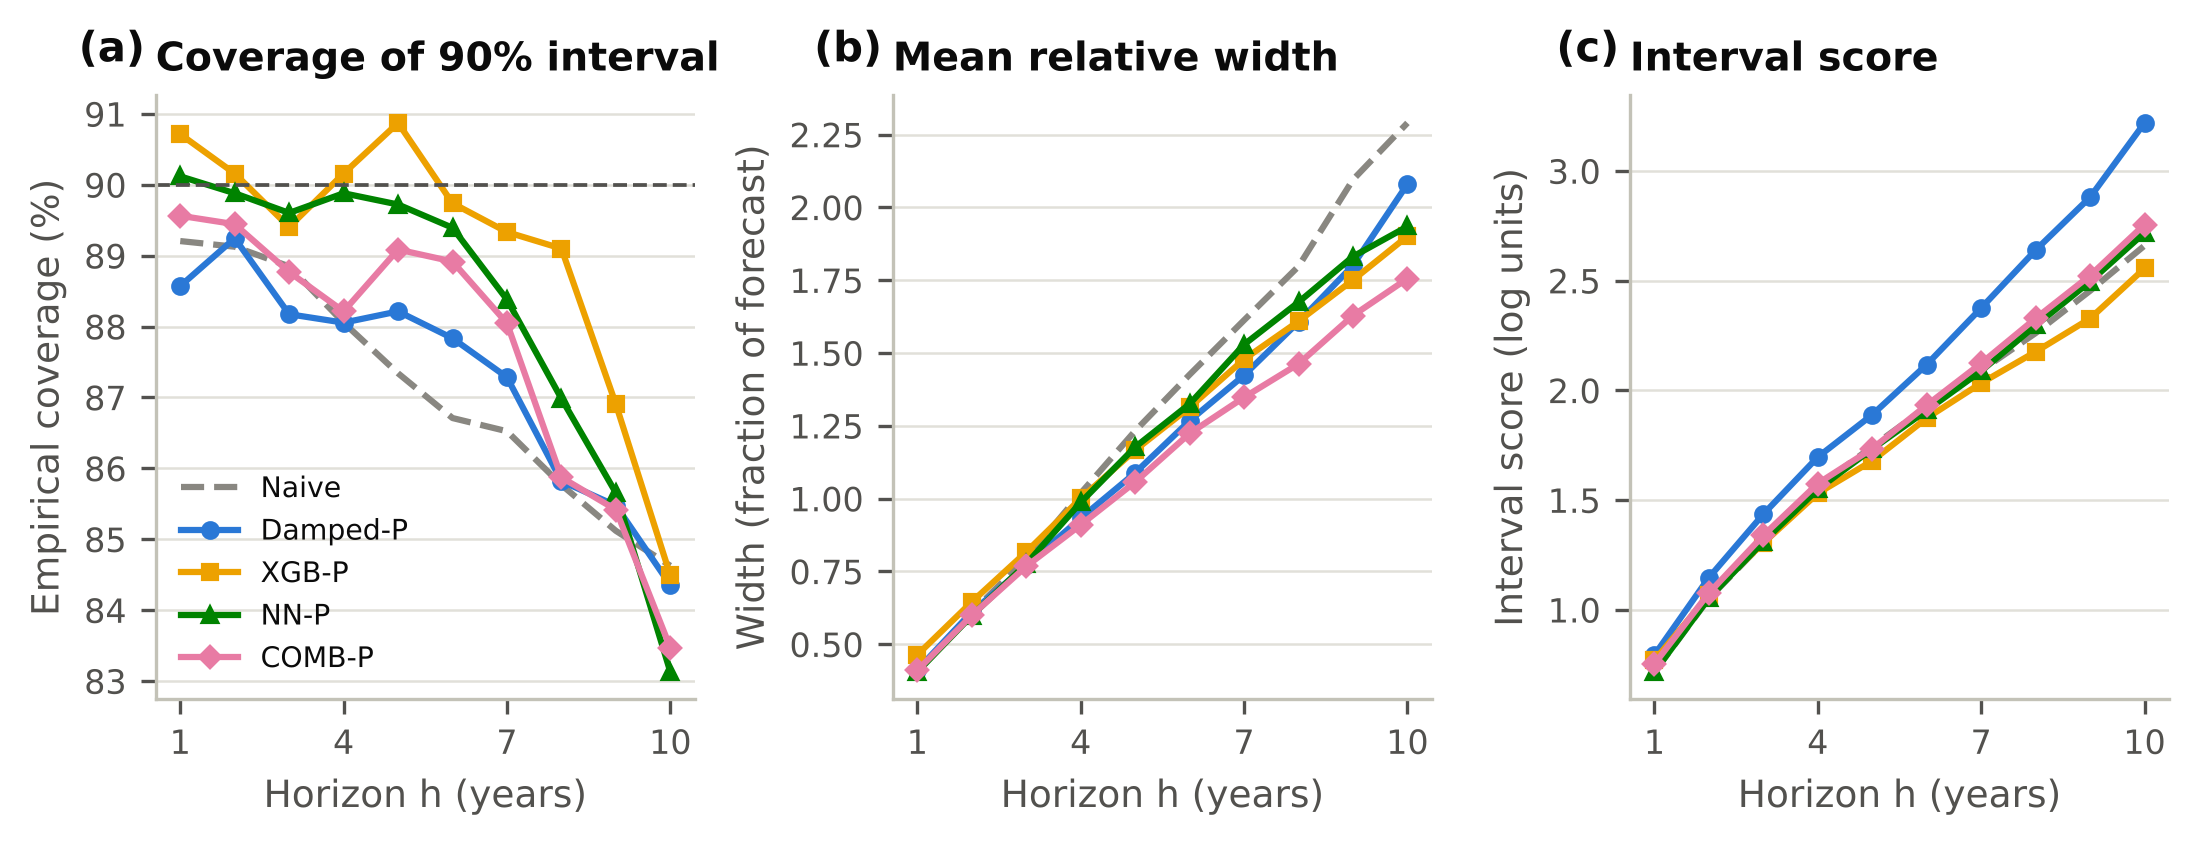

In [20]:
fig("fig8_intervals.png")

## 7. Projections to 2030 (Table 5, Fig. 9)

In [21]:
pp = pd.read_csv("results/projections_panel_COMB-P.csv")
pp.pivot(index="year", columns="source", values="proj").round(0)

source,cement,coal,flaring,gas,oil
year,,,,,
2025,1254.0,14557.0,354.0,6610.0,8906.0
2026,1276.0,14779.0,355.0,6726.0,8971.0
2027,1300.0,15044.0,357.0,6833.0,9052.0
2028,1323.0,15344.0,357.0,6954.0,9113.0
2029,1350.0,15635.0,359.0,7068.0,9186.0
2030,1374.0,15897.0,362.0,7167.0,9259.0


In [22]:
pr = pd.read_csv("results/projections_COMB-P.csv")
chk = pr[(pr.source == "total") & (pr.year == 2025) & pr.country.isin(["China", "India", "United States"])].copy()
chk["proj_change_%"] = 100 * (chk.proj / chk.base_2024 - 1)
chk["lo90_%"] = 100 * (chk.lo90 / chk.base_2024 - 1); chk["hi90_%"] = 100 * (chk.hi90 / chk.base_2024 - 1)
chk["GCB_2025_preliminary_%"] = chk.country.map({"China": 0.4, "India": 1.4, "United States": 1.9})
chk[["country", "proj_change_%", "lo90_%", "hi90_%", "GCB_2025_preliminary_%"]].round(1)

,country,proj_change_%,lo90_%,hi90_%,GCB_2025_preliminary_%
257,China,3.7,-7.1,13.8,0.4
545,India,7.3,-3.9,17.8,1.4
1409,United States,-1.3,-11.6,8.3,1.9


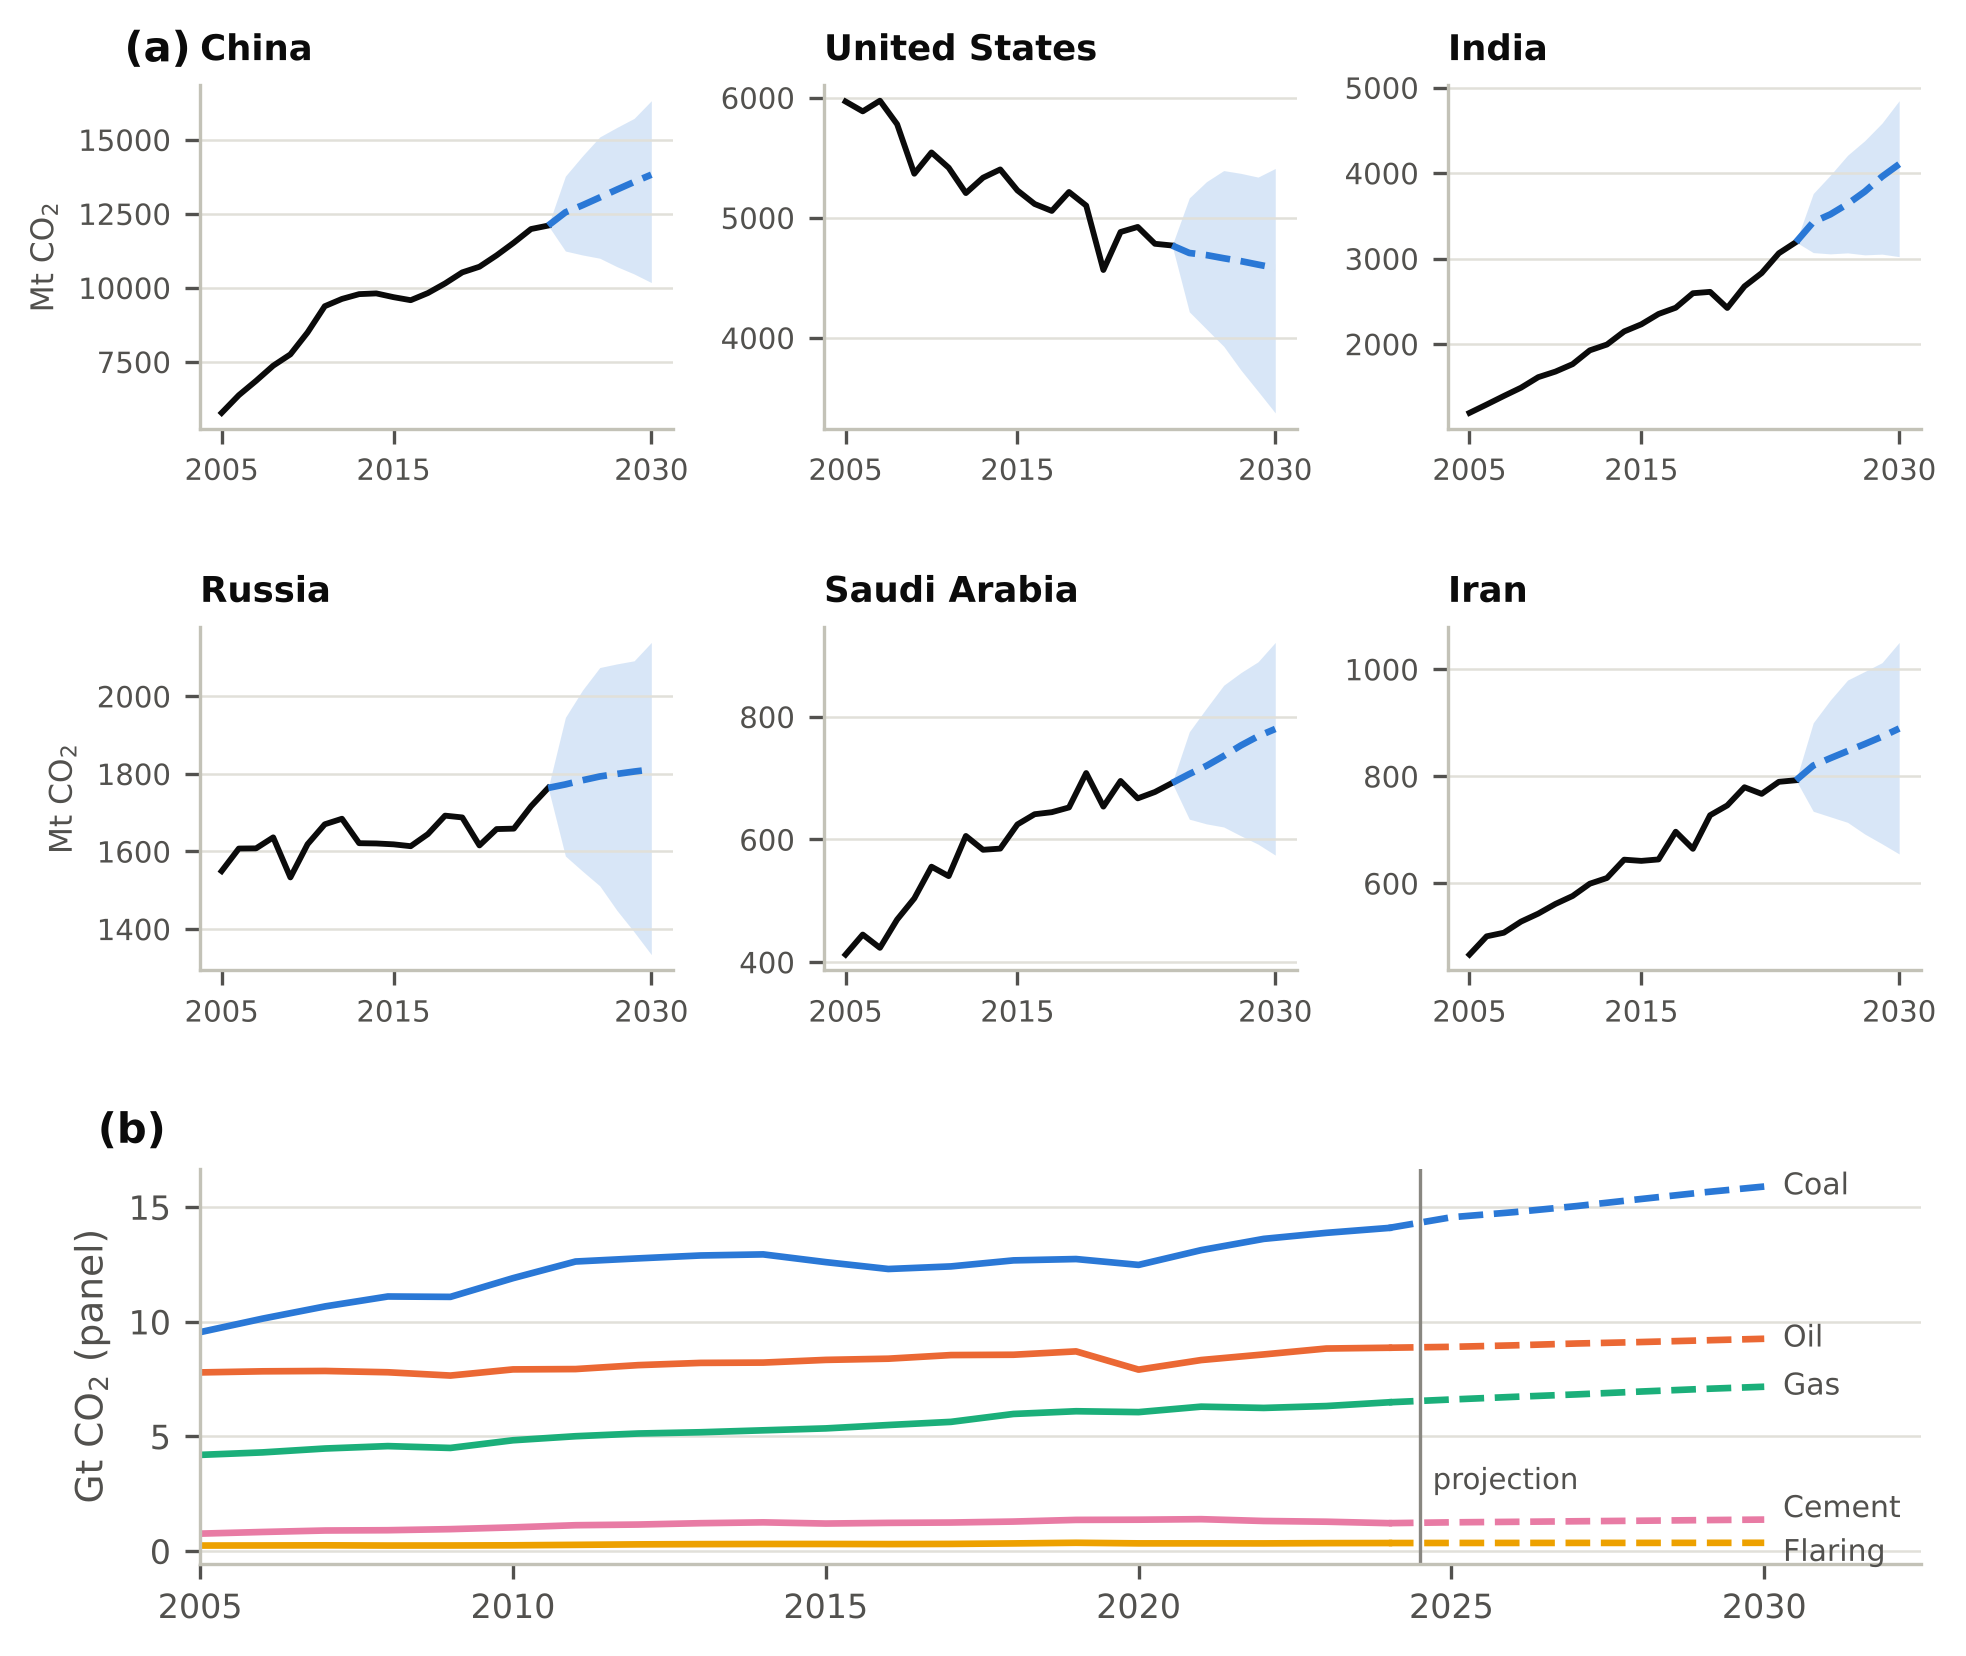

In [23]:
fig("fig9_projections.png")

## 8. Re-running the light steps
Uncomment to recompute the evaluation, projections and figures from the saved model outputs
(about 2 minutes; projections retrain XGBoost on all data, about 1 minute).

In [24]:
# !python3 -I src/evaluate.py
# !python3 -I src/project.py COMB-P XGB-P damped-P
# !python3 -I src/fig_results.py && python3 -I src/fig_extra.py COMB-P